# Uber Fare Prediction

Predict the price of the Uber ride using Linear Regression and Random Forest Regression. Preprocess data, detect outliers, and perform correlation analysis.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

df = pd.read_csv("/kaggle/input/datasets/yasserh/uber-fares-dataset/uber.csv")
print("Original dataset shape:", df.shape)
print(df.head())

Original dataset shape: (200000, 9)
   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   
           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   
   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.77

In [ ]:
df = df[(df["fare_amount"] > 0) &
        (df["passenger_count"] > 0)]

# Calculate distance using Haversine formula
def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

df["distance"] = haversine(
    df["pickup_latitude"], df["pickup_longitude"],
    df["dropoff_latitude"], df["dropoff_longitude"]
)
df = df[df["distance"] < 100]

Number of outliers: 5526


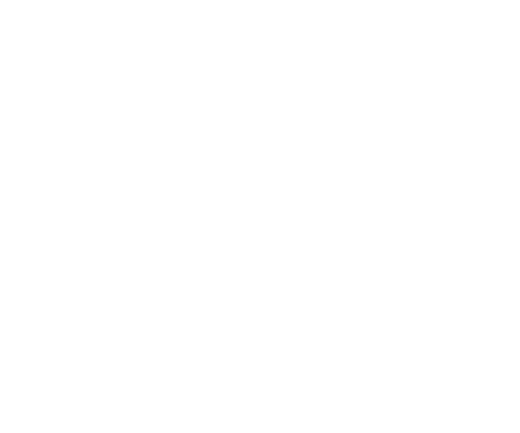

In [ ]:
# 3. Identify outliers using IQR
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)
IQR = Q3 - Q1
outliers = df[
    (df["fare_amount"] < Q1 - 1.5 * IQR) |
    (df["fare_amount"] > Q3 + 1.5 * IQR)
]
print("Number of outliers:", len(outliers))
sns.boxplot(x=df["fare_amount"])
plt.show()

fare_amount          1.000000
pickup_longitude     0.002527
pickup_latitude     -0.003346
dropoff_longitude    0.003155
dropoff_latitude    -0.003485
passenger_count      0.015849
distance_km          0.695237
pickup_hour         -0.004725
pickup_day           0.005391
pickup_month         0.025719
pickup_weekday       0.017348
distance             0.695237
Name: fare_amount, dtype: float64


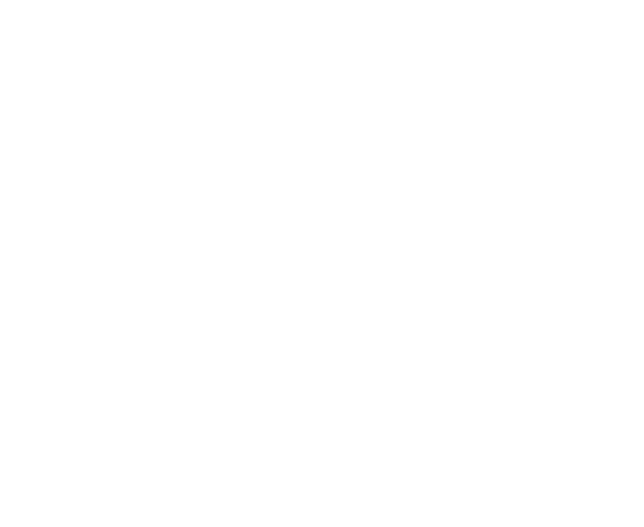

In [ ]:
df = df[df["fare_amount"].between(
    Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
)]
print(df.select_dtypes(include="number").corr()["fare_amount"])
sns.heatmap(df.select_dtypes(include="number").corr(),
            annot=True, cmap="coolwarm")
plt.show()

In [ ]:
X = df[[
    "pickup_longitude", "pickup_latitude",
    "dropoff_longitude", "dropoff_latitude",
    "passenger_count", "distance"
]]
y = df["fare_amount"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)
rf = RandomForestRegressor(
    n_estimators=100, random_state=42
)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
for name, pred in [
    ("Linear Regression", y_pred_lr),
    ("Random Forest", y_pred_rf)
]:
    print("\n", name)
    print("R2 Score:", r2_score(y_test, pred))
    print("RMSE:", np.sqrt(mean_squared_error(y_test, pred)))
    print("MSE:", mean_squared_error(y_test, pred))


 Linear Regression
R2 Score: 0.5175817418756437
RMSE: 2.5315413617288014
MSE: 6.408701666143713

 Random Forest
R2 Score: 0.711737531469202
RMSE: 1.956893587463422
MSE: 3.8294325126554614
